# NaFeGaPO4 convergence

Five independent online Bayesian-ridge runs for `NaFeGaPO4_nNa16`. Each curve is the best energy found so far. Runs that stop early (patience 30) keep that best energy out to evaluation 200, so the mean and ±1σ stay defined on the full axis.

In [1]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import numpy as np

ROOT = Path(
    "/home/mahpe/Code/Agentic_optimizer/Runs/runs/independent_global_optimizations/NaFeGaPO4_nNa16"
)
MAX_EVAL = 200
RUN_COLORS = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728", "#9467bd"]

grid = np.arange(MAX_EVAL + 1)
runs = []
for seed in range(5):
    path = ROOT / f"nafega_nNa16_bayesian_mace_seed{seed}" / "summary.json"
    data = json.loads(path.read_text())
    steps = data["steps"]
    x = np.array([int(step["step"]) for step in steps])
    y = np.array([float(step["best_energy_eV"]) for step in steps])
    if not np.array_equal(x, np.arange(len(x))):
        raise ValueError(f"seed {seed} steps are not 0..n-1")
    held = np.empty(MAX_EVAL + 1)
    held[: len(y)] = y
    held[len(y) :] = y[-1]
    runs.append(
        {
            "seed": seed,
            "x": x,
            "y": y,
            "held": held,
            "best": float(data["best_energy_eV"]),
            "best_first_step": int(data["best_first_step"]),
            "final_step": int(steps[-1]["step"]),
            "stopping_reason": data["stopping_reason"],
        }
    )

stack = np.vstack([run["held"] for run in runs])
mean = stack.mean(axis=0)
std = stack.std(axis=0, ddof=1)
lowest = min(run["best"] for run in runs)

for run in runs:
    print(
        f"Run {run['seed'] + 1}: best {run['best']:.6f} eV "
        f"at evaluation {run['best_first_step']}, "
        f"stopped at {run['final_step']} ({run['stopping_reason']})"
    )
print(f"Lowest: {lowest:.6f} eV")

Run 1: best -1086.221979 eV at evaluation 73, stopped at 103 (no_improvement_30)
Run 2: best -1086.032643 eV at evaluation 41, stopped at 71 (no_improvement_30)
Run 3: best -1085.806570 eV at evaluation 39, stopped at 69 (no_improvement_30)
Run 4: best -1085.813606 eV at evaluation 32, stopped at 62 (no_improvement_30)
Run 5: best -1085.793350 eV at evaluation 78, stopped at 108 (no_improvement_30)
Lowest: -1086.221979 eV


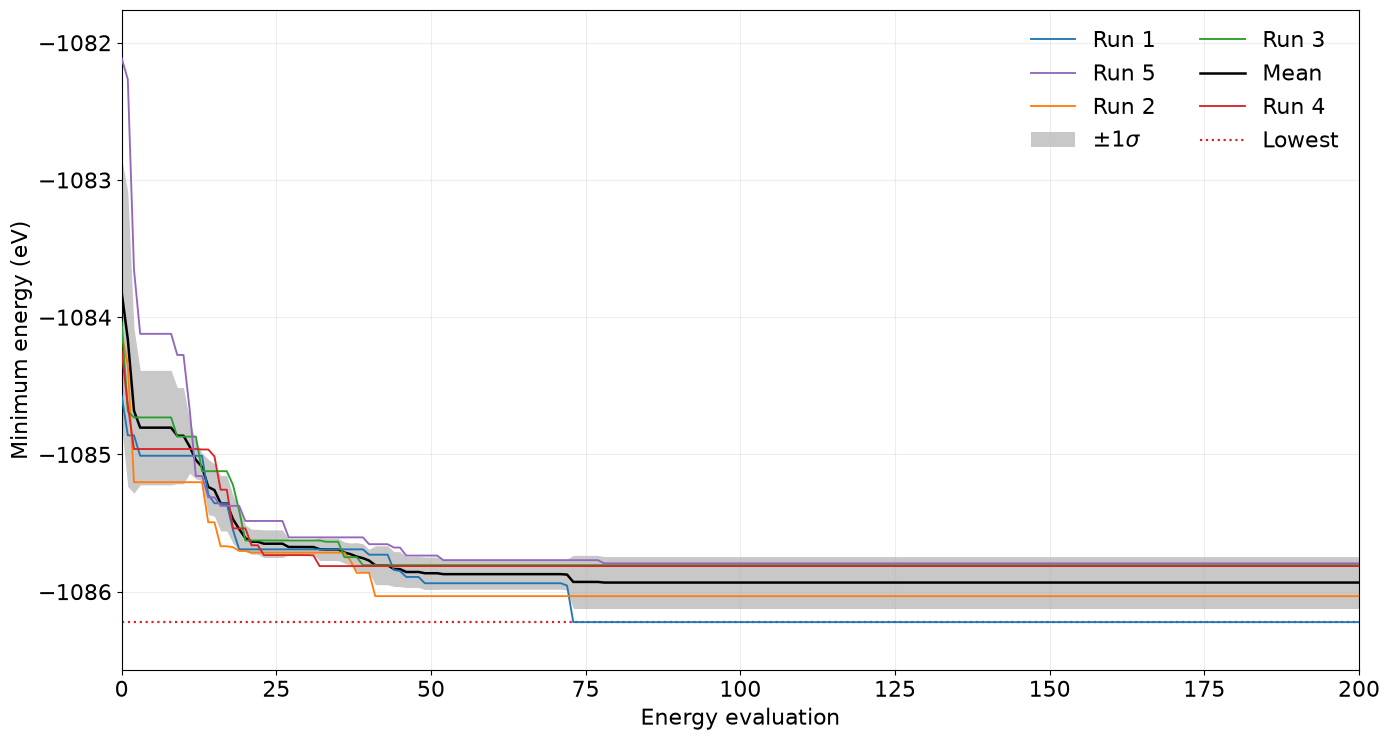

In [5]:
fig, ax = plt.subplots(figsize=(14, 7.5))
fontsize = 16

band = ax.fill_between(
    grid,
    mean - std,
    mean + std,
    color="0.75",
    alpha=0.85,
    linewidth=0,
    zorder=1,
    label=r"$\pm 1\sigma$",
)
mean_line, = ax.plot(grid, mean, color="black", lw=1.8, zorder=3, label="Mean")
lowest_line = ax.axhline(
    lowest, color="#d62728", ls=":", lw=1.6, zorder=2, label="Lowest"
)

run_lines = []
for run, color in zip(runs, RUN_COLORS):
    line, = ax.plot(
        grid,
        run["held"],
        color=color,
        lw=1.35,
        zorder=4,
        label=f"Run {run['seed'] + 1}",
    )
    run_lines.append(line)

ax.set_xlim(0, MAX_EVAL)
ax.set_ylim(stack.min() - 0.35, stack.max() + 0.35)
ax.set_xlabel("Energy evaluation", fontsize=fontsize)
ax.set_ylabel("Minimum energy (eV)", fontsize=fontsize)
ax.tick_params(axis='both', labelsize=fontsize)

handles = [
    run_lines[0],
    run_lines[4],
    run_lines[1],
    band,
    run_lines[2],
    mean_line,
    run_lines[3],
    lowest_line,
]
labels = [h.get_label() for h in handles]
ax.grid(alpha=.22)
ax.legend(handles, labels, loc="upper right", ncol=2, frameon=False, fontsize=fontsize)
fig.tight_layout()
plt.show()